# 09. Evaluación y comparación del modelo 1D-CNN

**Objetivo:** evaluar experimentalmente la nueva arquitectura 1D-CNN mediante Accuracy, Precision, Recall, F1-score, matriz de confusión y ROC-AUC.

La arquitectura utilizada es la definida en el experimento anterior y se mantiene sin modificaciones para garantizar la comparabilidad de los resultados.

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Semilla:", SEED)

TensorFlow: 2.21.0
Semilla: 42


## 1. Carga del conjunto experimental

Se utiliza la muestra estratificada de 15,000 registros generada durante la auditoría del dataset. La variable `id` no se utiliza como predictor y `cardio` constituye la variable objetivo.

In [2]:
DATA_PATH = Path("../../resultados/nuevo_experimento/cardio_15000.csv")
OUT_DIR = Path("../../resultados/nuevo_experimento")
FIG_DIR = OUT_DIR / "figuras"
TAB_DIR = OUT_DIR / "tablas"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, sep=";")

print("Dimensiones:", df.shape)
print("Nulos:", int(df.isnull().sum().sum()))
print("Duplicados:", int(df.duplicated().sum()))
print("Distribución:")
print(df["cardio"].value_counts().sort_index())

Dimensiones: (15000, 13)
Nulos: 0
Duplicados: 0
Distribución:
cardio
0    7579
1    7421
Name: count, dtype: int64


## 2. Preparación de los datos

Se excluye `id` por ser un identificador y no una característica clínica. La edad se transforma de días a años. Los datos se dividen de manera estratificada en entrenamiento y prueba. Posteriormente se reserva el 20 % del conjunto de entrenamiento para validación.

In [3]:
data = df.copy()

data["age"] = data["age"] / 365.25

X = data.drop(columns=["id", "cardio"])
y = data["cardio"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=SEED,
    stratify=y
)

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = X_train_scaled.astype("float32")
X_test_scaled = X_test_scaled.astype("float32")

y_train = y_train.to_numpy().astype("float32")
y_test = y_test.to_numpy().astype("float32")

print("X_train:", X_train_scaled.shape)
print("X_test:", X_test_scaled.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("Rango entrenamiento:",
      X_train_scaled.min(),
      X_train_scaled.max())

print("Rango prueba:",
      X_test_scaled.min(),
      X_test_scaled.max())

X_train: (12750, 11)
X_test: (2250, 11)
y_train: (12750,)
y_test: (2250,)
Rango entrenamiento: 0.0 1.0
Rango prueba: 0.0 1.0


## 3. Preparación de la entrada para la 1D-CNN

Cada observación contiene 11 variables predictoras. La red recibe los datos con una dimensión adicional para representar la estructura de entrada como una secuencia de 11 características.

In [4]:
X_train_cnn = X_train_scaled[..., np.newaxis]
X_test_cnn = X_test_scaled[..., np.newaxis]

print("Entrada CNN entrenamiento:", X_train_cnn.shape)
print("Entrada CNN prueba:", X_test_cnn.shape)

Entrada CNN entrenamiento: (12750, 11, 1)
Entrada CNN prueba: (2250, 11, 1)


## 4. Nueva arquitectura 1D-CNN

La arquitectura propuesta reduce considerablemente la cantidad de parámetros respecto del modelo de referencia.

- Conv1D: 32 filtros
- Conv1D: 96 filtros
- GlobalAveragePooling1D
- Dense: 256 neuronas
- Dropout: 0.30
- Salida Sigmoid

El objetivo es mantener una arquitectura suficientemente expresiva, pero con una cantidad de parámetros comprendida aproximadamente entre 30,000 y 50,000.

In [5]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    Input(shape=(11, 1)),

    Conv1D(
        filters=32,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    Conv1D(
        filters=96,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    GlobalAveragePooling1D(),

    Dense(
        256,
        activation="relu"
    ),

    Dropout(0.30),

    Dense(
        1,
        activation="sigmoid"
    )
])

model.compile(
    optimizer=Adam(),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape            ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 11, 32)          │           128 │
├─────────────────────────────────┼─────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 11, 96)          │         9,312 │
├─────────────────────────────────┼─────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 96)              │             0 │
│ (GlobalAveragePooling1D)        │                         │               │
├─────────────────────────────────┼─────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)             │        24,832 │
├─────────────────────────────────┼─────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)             │             0 │
├─────────────────────────────────┼─────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)               │           257 │
└─────────────────────────────────┴─────────────────────────┴───────────────┘

 Total params: 34,529 (134.88 KB)

 Trainable params: 34,529 (134.88 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
total_params = model.count_params()

print("Parámetros totales:", total_params)

assert total_params == 34529

print("Verificación satisfactoria: 34,529 parámetros.")

Parámetros totales: 34529
Verificación satisfactoria: 34,529 parámetros.


## 5. Entrenamiento

Se utiliza el 20 % del conjunto de entrenamiento como validación interna. Se emplea EarlyStopping para detener el entrenamiento cuando la pérdida de validación deja de mejorar.

In [7]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_cnn,
    y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print("Épocas ejecutadas:", len(history.history["loss"]))

Epoch 1/100


  1/319 ━━━━━━━━━━━━━━━━━━━━ 15:04 3s/step - accuracy: 0.5312 - loss: 0.6937

 13/319 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5120 - loss: 0.6926  

 28/319 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5112 - loss: 0.6925

 42/319 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5022 - loss: 0.6922

...

283/319 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7360 - loss: 0.5371

301/319 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7345 - loss: 0.5394

319/319 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7345 - loss: 0.5405

319/319 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7345 - loss: 0.5405 - val_accuracy: 0.7271 - val_loss: 0.5515


Épocas ejecutadas: 66


## 6. Evaluación sobre el conjunto de prueba

Las predicciones se convierten en probabilidades y posteriormente se utiliza un umbral de 0.5 para determinar la clase final.

In [8]:
y_prob = model.predict(
    X_test_cnn,
    verbose=0
).ravel()

y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

metrics = pd.DataFrame({
    "Metrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Valor": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

print(metrics.to_string(index=False))

metrics.to_csv(
    TAB_DIR / "metricas_evaluacion.csv",
    index=False
)

  Metrica    Valor
 Accuracy 0.731111
Precision 0.732601
   Recall 0.718778
 F1-score 0.725624
  ROC-AUC 0.788458


## 7. Reporte de clasificación

In [9]:
report = classification_report(
    y_test,
    y_pred,
    target_names=["Sin enfermedad", "Con enfermedad"],
    digits=4,
    zero_division=0
)

print(report)

with open(
    OUT_DIR / "classification_report.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(report)

                precision    recall  f1-score   support

Sin enfermedad     0.7297    0.7432    0.7364      1137
Con enfermedad     0.7326    0.7188    0.7256      1113

      accuracy                         0.7311      2250
     macro avg     0.7312    0.7310    0.7310      2250
  weighted avg     0.7311    0.7311    0.7311      2250



## 8. Matriz de confusión

La matriz de confusión permite observar los aciertos y errores de clasificación de cada clase.

Matriz de confusión:
[[845 292]
 [313 800]]


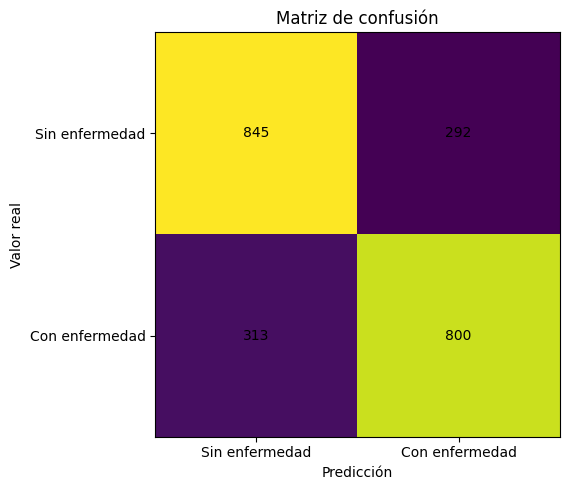

In [10]:
cm = confusion_matrix(y_test, y_pred)

print("Matriz de confusión:")
print(cm)

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(cm)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels([
    "Sin enfermedad",
    "Con enfermedad"
])

ax.set_yticklabels([
    "Sin enfermedad",
    "Con enfermedad"
])

ax.set_xlabel("Predicción")
ax.set_ylabel("Valor real")
ax.set_title("Matriz de confusión")

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

fig.tight_layout()
fig.savefig(
    FIG_DIR / "matriz_confusion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 9. Curva ROC

La curva ROC representa la relación entre la tasa de verdaderos positivos y la tasa de falsos positivos para diferentes umbrales de clasificación.

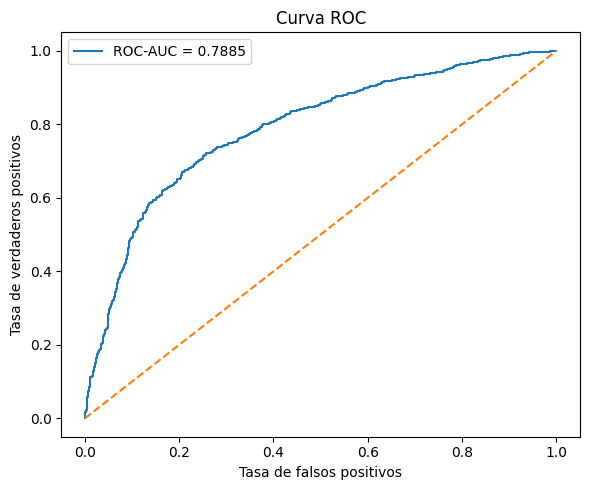

In [11]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

fig, ax = plt.subplots(figsize=(6, 5))

ax.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.4f}"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("Curva ROC")
ax.legend()

fig.tight_layout()

fig.savefig(
    FIG_DIR / "curva_roc.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 10. Evolución del entrenamiento

Se analizan las curvas de pérdida y accuracy para identificar diferencias entre entrenamiento y validación.

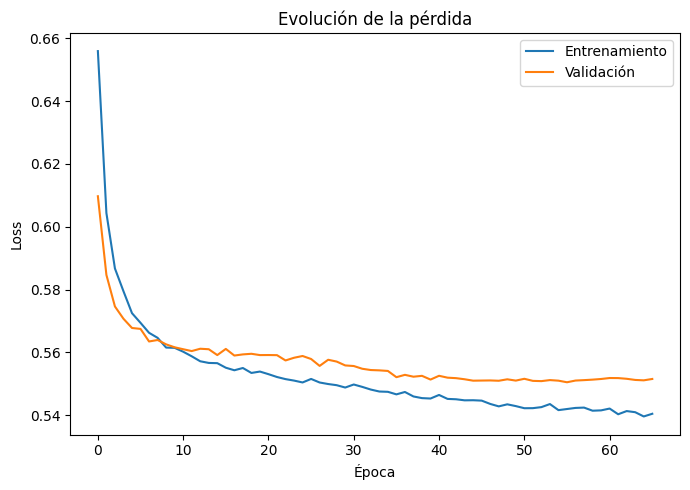

In [12]:
history_df = pd.DataFrame(history.history)

history_df.to_csv(
    TAB_DIR / "historial_entrenamiento.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    history_df["loss"],
    label="Entrenamiento"
)

ax.plot(
    history_df["val_loss"],
    label="Validación"
)

ax.set_xlabel("Época")
ax.set_ylabel("Loss")
ax.set_title("Evolución de la pérdida")
ax.legend()

fig.tight_layout()

fig.savefig(
    FIG_DIR / "curva_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

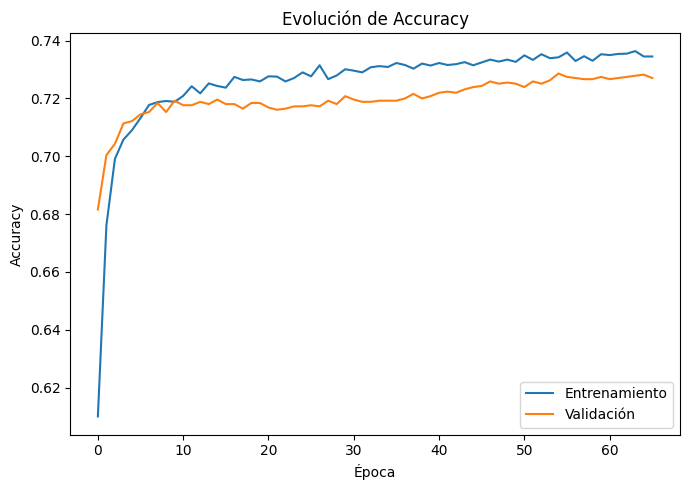

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    history_df["accuracy"],
    label="Entrenamiento"
)

ax.plot(
    history_df["val_accuracy"],
    label="Validación"
)

ax.set_xlabel("Época")
ax.set_ylabel("Accuracy")
ax.set_title("Evolución de Accuracy")
ax.legend()

fig.tight_layout()

fig.savefig(
    FIG_DIR / "curva_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11. Guardado del modelo

El modelo entrenado se guarda para evitar repetir el entrenamiento en las siguientes etapas del proyecto.

In [14]:
model_path = OUT_DIR / "modelo_nueva_cnn.keras"

model.save(model_path)

np.save(
    OUT_DIR / "y_test.npy",
    y_test
)

np.save(
    OUT_DIR / "y_prob.npy",
    y_prob
)

np.save(
    OUT_DIR / "y_pred.npy",
    y_pred
)

print("Modelo guardado en:", model_path)
print("Predicciones guardadas.")

Modelo guardado en: ..\..\resultados\nuevo_experimento\modelo_nueva_cnn.keras
Predicciones guardadas.


## 12. Resumen final

La nueva arquitectura 1D-CNN se evalúa mediante cinco métricas principales: Accuracy, Precision, Recall, F1-score y ROC-AUC. También se almacenan la matriz de confusión, las curvas de entrenamiento y la curva ROC para facilitar el análisis posterior.

In [15]:
print("=" * 55)
print("RESUMEN DEL EXPERIMENTO")
print("=" * 55)

print(f"Registros totales: {len(df)}")
print(f"Variables predictoras: {X.shape[1]}")
print(f"Parámetros del modelo: {total_params}")
print(f"Épocas ejecutadas: {len(history.history['loss'])}")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print()
print("Archivos de resultados generados correctamente.")

RESUMEN DEL EXPERIMENTO
Registros totales: 15000
Variables predictoras: 11
Parámetros del modelo: 34529
Épocas ejecutadas: 66
Accuracy:  0.7311
Precision: 0.7326
Recall:    0.7188
F1-score:  0.7256
ROC-AUC:   0.7885

Archivos de resultados generados correctamente.


## 13. Conclusión

La evaluación permite determinar el desempeño de la arquitectura 1D-CNN modificada sobre el conjunto de prueba. Las métricas obtenidas, junto con la matriz de confusión y la curva ROC, constituyen la evidencia experimental necesaria para analizar el comportamiento del modelo. Los resultados serán utilizados posteriormente para comparar la arquitectura propuesta con el modelo de referencia y analizar la relación entre complejidad y desempeño.